In [52]:
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.lda import LDA
from src.knn import KNN
from src.gmm import GMMClassifier
from src.svm import LinearSVM
from src.pca import PCA 
DATA_PATH = Path(r"C:\Users\hp\OneDrive\Desktop\ml lab8\team8\data\data.pkl")

In [53]:
#open and load/read the file
with DATA_PATH.open("rb") as file:
    data = pickle.load(file)


if not isinstance(data, dict):
    raise TypeError("Expected a dictionary containing 'x' and 'y'.")

if not {"x", "y"}.issubset(data):
    raise KeyError(f"Expected keys 'x' and 'y'. Found: {list(data.keys())}")

X = np.asarray(data["x"])
y = np.asarray(data["y"])

if X.ndim != 2:
    raise ValueError(f"X must be a 2D array. Found shape: {X.shape}")

if y.ndim != 1:
    raise ValueError(f"y must be a 1D array. Found shape: {y.shape}")

if X.shape[0] != y.shape[0]:
    raise ValueError("The number of samples and labels does not match.")

if X.shape[1] != 16:
    raise ValueError(f"Expected 16 features. Found: {X.shape[1]}")

if not np.issubdtype(X.dtype, np.number):
    raise TypeError("Features must be numeric.")

if not np.isfinite(X).all():
    raise ValueError("Features contain missing or infinite values.")

if not np.isin(y, [0, 1]).all():
    raise ValueError("Expected class labels 0 and 1.")

# Display basic information.
print("Dataset loaded successfully.")
print("Feature shape:", X.shape)
print("Label shape:", y.shape)
classes, counts = np.unique(y, return_counts=True)

class_summary = pd.DataFrame({
    "Class": classes,
    "Sample count": counts,
    "Percentage": 100 * counts / len(y)
})

print("\nClass distribution:")
print(class_summary.to_string(index=False))

feature_names = [f"x{i + 1}" for i in range(X.shape[1])]
preview = pd.DataFrame(X[:5], columns=feature_names)
preview["label"] = y[:5]

print("\nFirst five samples:")
print(preview.to_string(index=False))

Dataset loaded successfully.
Feature shape: (20000, 16)
Label shape: (20000,)

Class distribution:
 Class  Sample count  Percentage
     0         10000        50.0
     1         10000        50.0

First five samples:
        x1         x2         x3         x4         x5        x6         x7         x8         x9        x10        x11        x12        x13        x14        x15        x16  label
 29.259501  16.848943   6.268739  -6.310603  29.430830  1.412342  10.055510  33.893824  21.018188  15.093344  29.777387  -0.348396 -12.211845  10.646625  18.772909  13.580669      1
-28.875533  32.221666  -1.734529 -34.826586 -10.203239 13.900232 -17.372291 -10.307637  16.512852  30.595830 -15.626337   4.579222  -4.174866   3.194396 -22.657561  16.834274      0
-23.213924  -6.060101  13.624124   7.886931 -12.646328 11.710807  10.664065   0.668234  32.638534  -4.986447 -21.241645  -3.729688  32.436249  -7.565644   6.994269  43.480763      1
  8.267935 -12.658617 -14.408124  23.324225  43.84994

In [54]:
#Splitting of the data
train_indices = []
val_indices = []
test_indices = []

for class_label in np.unique(y):
    # Find the row positions belonging to this class.
    class_indices = np.flatnonzero(y == class_label)

    positions = np.arange(len(class_indices))

    # Deterministic allocation within each group of five samples.
    val_indices.extend(class_indices[positions % 5 == 0])
    test_indices.extend(class_indices[positions % 5 == 1])
    train_indices.extend(class_indices[positions % 5 >= 2])

# Sort the indices to preserve the original row order within each split.
train_indices = np.sort(np.asarray(train_indices, dtype=int))
val_indices = np.sort(np.asarray(val_indices, dtype=int))
test_indices = np.sort(np.asarray(test_indices, dtype=int))

# Extract features and their corresponding labels.
X_train = X[train_indices]
y_train = y[train_indices]

X_val = X[val_indices]
y_val = y[val_indices]

X_test = X[test_indices]
y_test = y[test_indices]

# Verify that no row appears in more than one split.
assert np.intersect1d(train_indices, val_indices).size == 0
assert np.intersect1d(train_indices, test_indices).size == 0
assert np.intersect1d(val_indices, test_indices).size == 0

assert (
    len(train_indices) + len(val_indices) + len(test_indices)
    == len(y)
)

# Display split sizes and class counts.
split_rows = []

for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    split_rows.append({
        "Split": name,
        "Samples": len(labels),
        "Class 0": np.sum(labels == 0),
        "Class 1": np.sum(labels == 1)
    })

print(pd.DataFrame(split_rows).to_string(index=False))

     Split  Samples  Class 0  Class 1
  Training    12000     6000     6000
Validation     4000     2000     2000
   Testing     4000     2000     2000


In [55]:
#4
train_mean = X_train.mean(axis=0)
train_std = X_train.std(axis=0)


train_std_safe = np.where(train_std == 0, 1.0, train_std)

# Use the SAME training statistics for all three splits.
X_train_scaled = (X_train - train_mean) / train_std_safe
X_val_scaled = (X_val - train_mean) / train_std_safe
X_test_scaled = (X_test - train_mean) / train_std_safe


In [56]:
def accuracy_score_manual(y_true, y_pred):
    return np.mean(y_true == y_pred)


def confusion_matrix_manual(y_true, y_pred):
    matrix = np.zeros((2, 2), dtype=int)

    for actual, predicted in zip(y_true, y_pred):
        matrix[int(actual), int(predicted)] += 1

    return matrix


def show_evaluation(name, y_true, y_pred):
    accuracy = accuracy_score_manual(y_true, y_pred)
    matrix = confusion_matrix_manual(y_true, y_pred)

    print(f"{name} validation accuracy: {accuracy * 100:.2f}%")
    print("\nConfusion matrix:")

    print(pd.DataFrame(
        matrix,
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"]
    ))

    return accuracy

In [57]:
#LDA
#Train using only the standardized training data.
lda_model = LDA()
lda_model.fit(X_train_scaled, y_train)

# Predict validation labels.
lda_val_predictions = lda_model.predict(X_val_scaled)

# Evaluate and store the result.
lda_val_accuracy = show_evaluation(
    "LDA",
    y_val,
    lda_val_predictions
)

validation_results = [{
    "Classifier": "LDA",
    "Setting": "Shared covariance",
    "Validation accuracy (%)": 100 * lda_val_accuracy
}]

LDA validation accuracy: 84.60%

Confusion matrix:
          Predicted 0  Predicted 1
Actual 0         1692          308
Actual 1          308         1692


In [58]:
#KNN
knn_model = KNN(batch_size=128)
knn_model.fit(X_train_scaled, y_train)

neighbor_values = [3, 5, 7, 11]

knn_val_predictions = knn_model.predict_for_k_values(
    X_val_scaled,
    neighbor_values
)

knn_rows = []

for k in neighbor_values:
    accuracy = accuracy_score_manual(
        y_val, knn_val_predictions[k]
    )

    knn_rows.append({
        "Neighbours": k,
        "Validation accuracy (%)": 100 * accuracy
    })

knn_validation_table = pd.DataFrame(knn_rows)

print("KNN validation comparison:")
print(knn_validation_table.to_string(index=False))

# If accuracies tie, choose the first (smallest) k tested.
best_row = knn_validation_table[
    "Validation accuracy (%)"
].idxmax()

best_k = int(
    knn_validation_table.loc[best_row, "Neighbours"]
)

print(f"\nSelected number of neighbours: {best_k}")

best_knn_val_accuracy = show_evaluation(
    f"KNN (k={best_k})",
    y_val,
    knn_val_predictions[best_k]
)

# Update the comparison table without duplicating KNN on reruns.
validation_results = [
    row for row in validation_results
    if row["Classifier"] != "KNN"
]

validation_results.append({
    "Classifier": "KNN",
    "Setting": f"k={best_k}",
    "Validation accuracy (%)": 100 * best_knn_val_accuracy
})


KNN validation comparison:
 Neighbours  Validation accuracy (%)
          3                   99.775
          5                   99.825
          7                   99.875
         11                   99.825

Selected number of neighbours: 7
KNN (k=7) validation accuracy: 99.88%

Confusion matrix:
          Predicted 0  Predicted 1
Actual 0         2000            0
Actual 1            5         1995


In [59]:
#GMM
component_values = [1, 2, 3, 4]

gmm_models = {}
gmm_val_predictions = {}
gmm_rows = []

for components in component_values:
    print(
        f"Training GMM with {components} component(s) per class...",
        flush=True
    )

    model = GMMClassifier(
        n_components=components,
        max_iter=150,
        tol=1e-5,
        regularization=1e-5
    )

    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_val_scaled)

    accuracy = accuracy_score_manual(
        y_val, predictions
    )

    gmm_models[components] = model
    gmm_val_predictions[components] = predictions

    gmm_rows.append({
        "Components per class": components,
        "Validation accuracy (%)": 100 * accuracy,
        "Class 0 EM updates": model.models_[0].n_iter_,
        "Class 1 EM updates": model.models_[1].n_iter_,
        "Both converged": all(
            fitted_model.converged_
            for fitted_model in model.models_
        )
    })

gmm_validation_table = pd.DataFrame(gmm_rows)

print("\nGMM validation comparison:")
print(gmm_validation_table.to_string(index=False))

Training GMM with 1 component(s) per class...


Training GMM with 2 component(s) per class...
Training GMM with 3 component(s) per class...
Training GMM with 4 component(s) per class...

GMM validation comparison:
 Components per class  Validation accuracy (%)  Class 0 EM updates  Class 1 EM updates  Both converged
                    1                    97.35                   1                   1            True
                    2                    99.70                   7                   5            True
                    3                   100.00                   8                   6            True
                    4                   100.00                 100                  42            True


Selected components per class: 3

GMM (3 component(s) per class) validation accuracy: 100.00%

Confusion matrix:
          Predicted 0  Predicted 1
Actual 0         2000            0
Actual 1            0         2000


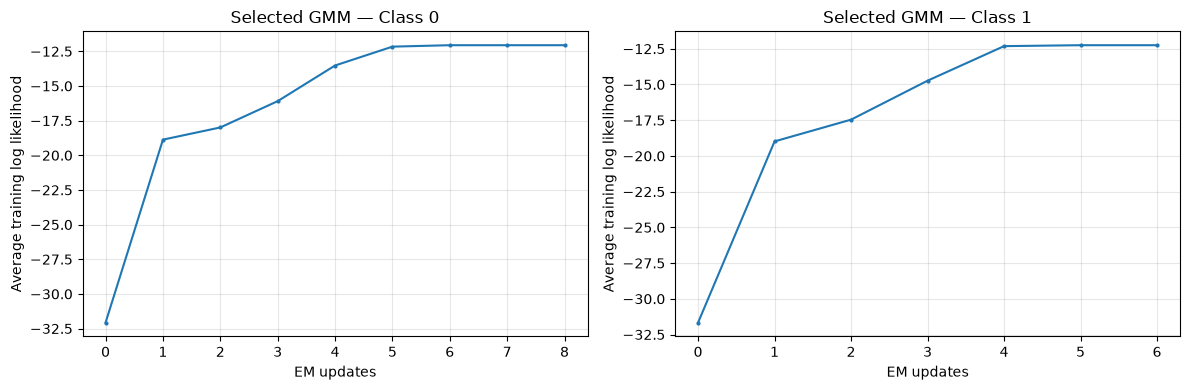

In [60]:
# Consider only candidates whose two class models converged.
converged_candidates = gmm_validation_table[
    gmm_validation_table["Both converged"]
].copy()

if converged_candidates.empty:
    raise RuntimeError(
        "No GMM candidate fully converged. "
        "Increase max_iter in Cell 14 and rerun it."
    )

ranked_candidates = converged_candidates.sort_values(
    by=["Validation accuracy (%)", "Components per class"],
    ascending=[False, True]
)

best_components = int(
    ranked_candidates.iloc[0]["Components per class"]
)

best_gmm_model = gmm_models[best_components]

print(
    f"Selected components per class: {best_components}\n"
)

best_gmm_val_accuracy = show_evaluation(
    f"GMM ({best_components} component(s) per class)",
    y_val,
    gmm_val_predictions[best_components]
)

# Plot the selected models' training log likelihoods.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, class_label, model in zip(
    axes,
    best_gmm_model.classes_,
    best_gmm_model.models_
):
    history = model.log_likelihood_history_

    ax.plot(
        range(len(history)),
        history,
        marker=".",
        markersize=4
    )

    ax.set_title(f"Selected GMM — Class {class_label}")
    ax.set_xlabel("EM updates")
    ax.set_ylabel("Average training log likelihood")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [61]:
#SVM
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]

svm_models = {}
svm_val_predictions = {}
svm_rows = []

for C in C_values:
    print(f"Training linear SVM with C={C}...", flush=True)

    model = LinearSVM(
        C=C,
        max_iter=2000
    )

    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_val_scaled)

    accuracy = accuracy_score_manual(
        y_val,
        predictions
    )

    svm_models[C] = model
    svm_val_predictions[C] = predictions

    svm_rows.append({
        "C": C,
        "Validation accuracy (%)": 100 * accuracy,
        "Iterations": model.n_iter_,
        "Converged": model.converged_
    })

    if not model.converged_:
        print(
            "Optimizer message:",
            model.optimization_result_.message
        )

svm_validation_table = pd.DataFrame(svm_rows)

print("\nLinear SVM validation comparison:")
print(svm_validation_table.to_string(index=False))

# Select only successfully optimized candidates.
converged_svm_candidates = svm_validation_table[
    svm_validation_table["Converged"]
].copy()

if converged_svm_candidates.empty:
    raise RuntimeError(
        "No SVM candidate converged. "
        "Check the optimizer messages before continuing."
    )

# Highest accuracy first; smaller C wins an accuracy tie.
ranked_svm_candidates = converged_svm_candidates.sort_values(
    by=["Validation accuracy (%)", "C"],
    ascending=[False, True]
)

best_C = float(ranked_svm_candidates.iloc[0]["C"])
best_svm_model = svm_models[best_C]

print(f"\nSelected C: {best_C}\n")

best_svm_val_accuracy = show_evaluation(
    f"Linear SVM (C={best_C})",
    y_val,
    svm_val_predictions[best_C]
)

Training linear SVM with C=0.01...
Training linear SVM with C=0.1...
Training linear SVM with C=1.0...
Training linear SVM with C=10.0...
Training linear SVM with C=100.0...

Linear SVM validation comparison:
     C  Validation accuracy (%)  Iterations  Converged
  0.01                   79.500           3       True
  0.10                   81.225           5       True
  1.00                   84.000          11       True
 10.00                   84.675          16       True
100.00                   84.775          18       True

Selected C: 100.0

Linear SVM (C=100.0) validation accuracy: 84.78%

Confusion matrix:
          Predicted 0  Predicted 1
Actual 0         1696          304
Actual 1          305         1695


In [62]:
validation_results = [
    {
        "Classifier": "LDA",
        "Setting": "Shared covariance",
        "Validation accuracy (%)": 100 * lda_val_accuracy
    },
    {
        "Classifier": "KNN",
        "Setting": f"k={best_k}",
        "Validation accuracy (%)": 100 * best_knn_val_accuracy
    },
    {
        "Classifier": "GMM",
        "Setting": f"{best_components} component(s) per class",
        "Validation accuracy (%)": 100 * best_gmm_val_accuracy
    },
    {
        "Classifier": "Linear SVM",
        "Setting": f"C={best_C}",
        "Validation accuracy (%)": 100 * best_svm_val_accuracy
    }
]

validation_comparison = pd.DataFrame(validation_results)

print("Original-feature validation comparison:")
print(validation_comparison.to_string(index=False))



Original-feature validation comparison:
Classifier                  Setting  Validation accuracy (%)
       LDA        Shared covariance                   84.600
       KNN                      k=7                   99.875
       GMM 3 component(s) per class                  100.000
Linear SVM                  C=100.0                   84.775


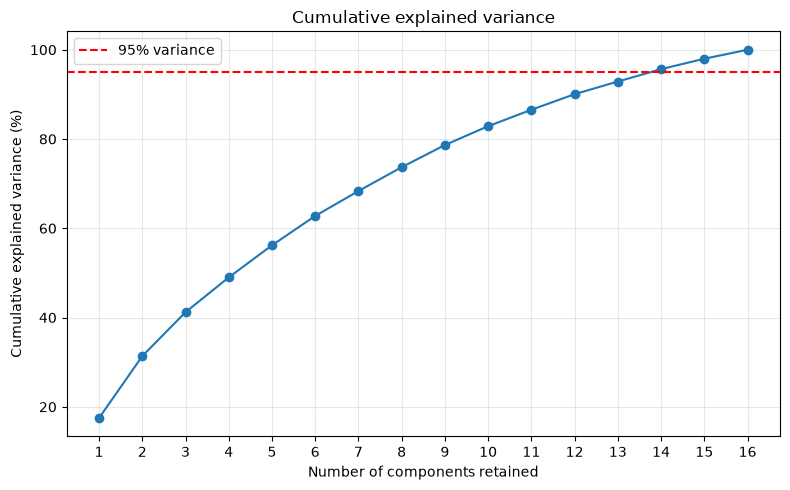

In [63]:
#PCA
# Fit PCA using standardized training data only.
pca_model = PCA()
pca_model.fit(X_train_scaled)

component_numbers = np.arange(1, X.shape[1] + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    component_numbers,
    100 * pca_model.cumulative_variance_,
    marker="o"
)

plt.axhline(
    95,
    color="red",
    linestyle="--",
    label="95% variance"
)

plt.xlabel("Number of components retained")
plt.ylabel("Cumulative explained variance (%)")
plt.title("Cumulative explained variance")
plt.xticks(component_numbers)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [64]:
K_values = [1, 2, 4, 8, 12, 16]

X_train_pca_all = pca_model.transform(
    X_train_scaled,
    n_components=X.shape[1]
)

X_val_pca_all = pca_model.transform(
    X_val_scaled,
    n_components=X.shape[1]
)

In [51]:
pca_results = []
pca_selected_models = {}
pca_tuning_rows = []

for K in K_values:
    print(f"\nProcessing PCA K={K}...", flush=True)

    train_features = X_train_pca_all[:, :K]
    val_features = X_val_pca_all[:, :K]

    # --------------------------------------------------
    # 1. LDA
    # --------------------------------------------------
    lda = LDA()
    lda.fit(train_features, y_train)

    lda_predictions = lda.predict(val_features)
    lda_accuracy = accuracy_score_manual(
        y_val, lda_predictions
    )

    # --------------------------------------------------
    # 2. KNN: select neighbour count
    # --------------------------------------------------
    knn = KNN(batch_size=128)
    knn.fit(train_features, y_train)

    knn_predictions = knn.predict_for_k_values(
        val_features, neighbor_values
    )

    knn_accuracies = {}

    for neighbours in neighbor_values:
        accuracy = accuracy_score_manual(
            y_val, knn_predictions[neighbours]
        )

        knn_accuracies[neighbours] = accuracy

        pca_tuning_rows.append({
            "K": K,
            "Classifier": "KNN",
            "Setting": f"k={neighbours}",
            "Validation accuracy (%)": 100 * accuracy,
            "Converged": True
        })

    selected_neighbours = max(
        sorted(knn_accuracies),
        key=lambda k: knn_accuracies[k]
    )

    knn_accuracy = knn_accuracies[selected_neighbours]

    # --------------------------------------------------
    # 3. GMM: select components per class
    # --------------------------------------------------
    selected_gmm = None
    selected_components = None
    gmm_accuracy = -np.inf

    for components in component_values:
        gmm = GMMClassifier(
            n_components=components,
            max_iter=300,
            tol=1e-5,
            regularization=1e-5
        )

        try:
            gmm.fit(train_features, y_train)

            predictions = gmm.predict(val_features)
            accuracy = accuracy_score_manual(y_val, predictions)

            converged = all(
                model.converged_ for model in gmm.models_
            )

        except (ValueError, np.linalg.LinAlgError) as error:
            print(
                f"  GMM components={components} failed: {error}",
                flush=True
            )

            pca_tuning_rows.append({
                "K": K,
                "Classifier": "GMM",
                "Setting": f"components={components}",
                "Validation accuracy (%)": np.nan,
                "Converged": False
            })

            continue

        pca_tuning_rows.append({
            "K": K,
            "Classifier": "GMM",
            "Setting": f"components={components}",
            "Validation accuracy (%)": 100 * accuracy,
            "Converged": converged
        })

        if not converged:
            print(
                f"  GMM components={components} "
                "did not converge; excluded from selection.",
                flush=True
            )

        # Sorted candidates and strict improvement:
        # smaller component count wins ties.
        if converged and accuracy > gmm_accuracy:
            selected_gmm = gmm
            selected_components = components
            gmm_accuracy = accuracy

    if selected_gmm is None:
        raise RuntimeError(
            f"No GMM candidate converged for K={K}. "
            "Inspect the diagnostics before continuing."
        )

    # --------------------------------------------------
    # 4. Linear SVM: select C
    # --------------------------------------------------
    selected_svm = None
    selected_C = None
    svm_accuracy = -np.inf

    for C in C_values:
        svm = LinearSVM(C=C, max_iter=2000)
        svm.fit(train_features, y_train)

        predictions = svm.predict(val_features)
        accuracy = accuracy_score_manual(y_val, predictions)

        pca_tuning_rows.append({
            "K": K,
            "Classifier": "Linear SVM",
            "Setting": f"C={C}",
            "Validation accuracy (%)": 100 * accuracy,
            "Converged": svm.converged_
        })

        if not svm.converged_:
            print(
                f"  SVM C={C} did not converge: "
                f"{svm.optimization_result_.message}",
                flush=True
            )

        if svm.converged_ and accuracy > svm_accuracy:
            selected_svm = svm
            selected_C = C
            svm_accuracy = accuracy

    if selected_svm is None:
        raise RuntimeError(
            f"No SVM candidate converged for K={K}."
        )

    # --------------------------------------------------
    # Store selected models and validation results
    # --------------------------------------------------
    pca_selected_models[K] = {
        "LDA": lda,
        "KNN": knn,
        "KNN neighbours": selected_neighbours,
        "GMM": selected_gmm,
        "GMM components": selected_components,
        "Linear SVM": selected_svm,
        "SVM C": selected_C
    }

    pca_results.append({
        "K": K,
        "Retained variance (%)": (
            100 * pca_model.cumulative_variance_[K - 1]
        ),
        "LDA": 100 * lda_accuracy,
        "KNN": 100 * knn_accuracy,
        "GMM": 100 * gmm_accuracy,
        "Linear SVM": 100 * svm_accuracy,
        "KNN neighbours": selected_neighbours,
        "GMM components": selected_components,
        "SVM C": selected_C
    })

    print(
        f"Completed K={K}: "
        f"LDA={100 * lda_accuracy:.3f}%, "
        f"KNN={100 * knn_accuracy:.3f}%, "
        f"GMM={100 * gmm_accuracy:.3f}%, "
        f"SVM={100 * svm_accuracy:.3f}%",
        flush=True
    )

pca_results_table = pd.DataFrame(pca_results)
pca_tuning_table = pd.DataFrame(pca_tuning_rows)

print("\nPCA validation results:")
print(pca_results_table.round(3).to_string(index=False))


Processing PCA K=1...
Completed K=1: LDA=60.800%, KNN=66.475%, GMM=68.625%, SVM=60.800%

Processing PCA K=2...
Completed K=2: LDA=68.725%, KNN=88.600%, GMM=89.575%, SVM=68.725%

Processing PCA K=4...
Completed K=4: LDA=69.850%, KNN=92.825%, GMM=93.600%, SVM=69.900%

Processing PCA K=8...
Completed K=8: LDA=82.775%, KNN=98.550%, GMM=98.900%, SVM=82.775%

Processing PCA K=12...
Completed K=12: LDA=83.250%, KNN=99.525%, GMM=99.925%, SVM=83.325%

Processing PCA K=16...
Completed K=16: LDA=84.600%, KNN=99.875%, GMM=100.000%, SVM=84.775%

PCA validation results:
 K  Retained variance (%)    LDA    KNN     GMM  Linear SVM  KNN neighbours  GMM components  SVM C
 1                 17.472 60.800 66.475  68.625      60.800              11               2   0.01
 2                 31.357 68.725 88.600  89.575      68.725              11               2  10.00
 4                 48.994 69.850 92.825  93.600      69.900              11               3 100.00
 8                 73.686 82.775 98.550 

In [65]:
#testing
classifier_names = ["LDA", "KNN", "GMM", "Linear SVM"]

# Predict using the models and settings already selected.
original_test_predictions = {
    "LDA": lda_model.predict(X_test_scaled),

    "KNN": knn_model.predict_for_k_values(
        X_test_scaled, [best_k]
    )[best_k],

    "GMM": best_gmm_model.predict(X_test_scaled),

    "Linear SVM": best_svm_model.predict(X_test_scaled)
}

original_settings = {
    "LDA": "Shared covariance",
    "KNN": f"k={best_k}",
    "GMM": f"{best_components} component(s) per class",
    "Linear SVM": f"C={best_C}"
}

original_test_rows = []

for classifier in classifier_names:
    predictions = original_test_predictions[classifier]

    correct = int(np.sum(predictions == y_test))
    errors = len(y_test) - correct

    original_test_rows.append({
        "Classifier": classifier,
        "Setting": original_settings[classifier],
        "Correct": correct,
        "Errors": errors,
        "Test accuracy (%)": 100 * correct / len(y_test)
    })

original_test_table = pd.DataFrame(original_test_rows)

print("Original 16 features — final test results:")
print(original_test_table.to_string(index=False))

Original 16 features — final test results:
Classifier                  Setting  Correct  Errors  Test accuracy (%)
       LDA        Shared covariance     3391     609             84.775
       KNN                      k=7     3990      10             99.750
       GMM 3 component(s) per class     4000       0            100.000
Linear SVM                  C=100.0     3383     617             84.575


In [66]:
#24 Transform test data without fitting PCA again.
X_test_pca_all = pca_model.transform(
    X_test_scaled,
    n_components=16
)

pca_test_predictions = {}
pca_test_rows = []

for K in K_values:

    test_features = X_test_pca_all[:, :K]
    selected = pca_selected_models[K]

    selected_neighbours = selected["KNN neighbours"]

    predictions = {
        "LDA": selected["LDA"].predict(test_features),

        "KNN": selected["KNN"].predict_for_k_values(
            test_features,
            [selected_neighbours]
        )[selected_neighbours],

        "GMM": selected["GMM"].predict(test_features),

        "Linear SVM": selected["Linear SVM"].predict(
            test_features
        )
    }

    pca_test_predictions[K] = predictions

    result_row = {
        "K": K,
        "Retained training variance (%)": (
            100 * pca_model.cumulative_variance_[K - 1]
        )
    }

    for classifier in classifier_names:
        result_row[classifier] = (
            100 * accuracy_score_manual(
                y_test,
                predictions[classifier]
            )
        )

    pca_test_rows.append(result_row)

pca_test_table = pd.DataFrame(pca_test_rows)


In [67]:
#25
original_test_accuracies = dict(zip(
    original_test_table["Classifier"],
    original_test_table["Test accuracy (%)"]
))

final_rows = [{
    "Representation": "Original 16 features",
    **{
        classifier: original_test_accuracies[classifier]
        for classifier in classifier_names
    }
}]

for _, row in pca_test_table.iterrows():
    final_rows.append({
        "Representation": f"PCA K={int(row['K'])}",
        **{
            classifier: row[classifier]
            for classifier in classifier_names
        }
    })

final_test_comparison = pd.DataFrame(final_rows)

print("Final comparison — TEST accuracy (%):")
print(final_test_comparison.round(3).to_string(index=False))

Final comparison — TEST accuracy (%):
      Representation    LDA    KNN     GMM  Linear SVM
Original 16 features 84.775 99.750 100.000      84.575
             PCA K=1 63.075 67.425  69.550      63.075
             PCA K=2 70.425 89.175  89.425      70.425
             PCA K=4 71.175 93.100  93.525      71.175
             PCA K=8 82.800 98.275  98.825      82.875
            PCA K=12 83.450 99.300  99.825      83.550
            PCA K=16 84.775 99.750 100.000      84.575


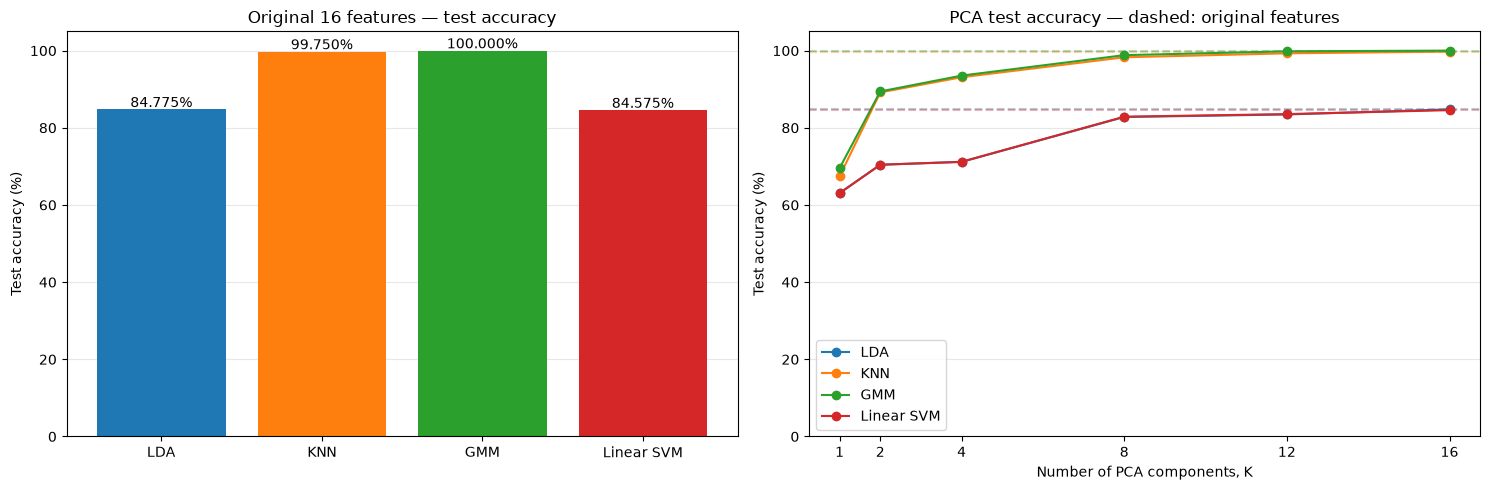

In [68]:
colors = {
    "LDA": "tab:blue",
    "KNN": "tab:orange",
    "GMM": "tab:green",
    "Linear SVM": "tab:red"
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Original-feature test accuracies.
bars = axes[0].bar(
    classifier_names,
    [
        original_test_accuracies[name]
        for name in classifier_names
    ],
    color=[colors[name] for name in classifier_names]
)

for bar, classifier in zip(bars, classifier_names):
    accuracy = original_test_accuracies[classifier]

    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 0.6,
        f"{accuracy:.3f}%",
        ha="center"
    )

axes[0].set_title("Original 16 features — test accuracy")
axes[0].set_ylabel("Test accuracy (%)")
axes[0].set_ylim(0, 105)

# PCA test accuracies.
for classifier in classifier_names:
    axes[1].plot(
        pca_test_table["K"],
        pca_test_table[classifier],
        marker="o",
        color=colors[classifier],
        label=classifier
    )

    axes[1].axhline(
        original_test_accuracies[classifier],
        color=colors[classifier],
        linestyle="--",
        alpha=0.35
    )

axes[1].set_title("PCA test accuracy — dashed: original features")
axes[1].set_xlabel("Number of PCA components, K")
axes[1].set_ylabel("Test accuracy (%)")
axes[1].set_xticks(K_values)
axes[1].set_ylim(0, 105)
axes[1].legend()

for ax in axes:
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [69]:
validation_accuracy_lookup = dict(zip(
    validation_comparison["Classifier"],
    validation_comparison["Validation accuracy (%)"]
))

validation_test_rows = []

for classifier in classifier_names:
    validation_accuracy = validation_accuracy_lookup[classifier]
    test_accuracy = original_test_accuracies[classifier]

    validation_test_rows.append({
        "Classifier": classifier,
        "Validation accuracy (%)": validation_accuracy,
        "Test accuracy (%)": test_accuracy,
        "Test minus validation (percentage points)": (
            test_accuracy - validation_accuracy
        )
    })

validation_test_comparison = pd.DataFrame(
    validation_test_rows
)

print("Original features — validation versus test:")
print(
    validation_test_comparison.round(3).to_string(index=False)
)

Original features — validation versus test:
Classifier  Validation accuracy (%)  Test accuracy (%)  Test minus validation (percentage points)
       LDA                   84.600             84.775                                      0.175
       KNN                   99.875             99.750                                     -0.125
       GMM                  100.000            100.000                                      0.000
Linear SVM                   84.775             84.575                                     -0.200


In [70]:
results = pca_results_table.melt(
    id_vars="K",
    value_vars=["LDA", "KNN", "GMM", "Linear SVM"],
    var_name="Classifier",
    value_name="Accuracy"
)

best_pca = results.sort_values(
    ["Accuracy", "K", "Classifier"],
    ascending=[False, True, True]
).iloc[0]

print("BEST PCA MODEL")
print("-------------------------")
print("Classifier:", best_pca["Classifier"])
print("PCA Components:", int(best_pca["K"]))
print(f"Validation Accuracy: {best_pca['Accuracy']:.3f}%")

BEST PCA MODEL
-------------------------
Classifier: GMM
PCA Components: 16
Validation Accuracy: 100.000%


In [71]:
selected_K = int(best_pca["K"])
selected_classifier = best_pca["Classifier"]

selected_test_accuracy = pca_test_table.set_index("K").loc[
    selected_K, selected_classifier
]

print("FINAL TEST RESULTS")
print("-------------------------")
print("Best Classifier:", selected_classifier)
print("PCA Components:", selected_K)
print(f"Test Accuracy: {selected_test_accuracy:.3f}%")

FINAL TEST RESULTS
-------------------------
Best Classifier: GMM
PCA Components: 16
Test Accuracy: 100.000%


## Discussion and Conclusion

GMM achieved the highest test accuracy of 100%, followed by KNN
at 99.750%. LDA and linear SVM achieved 84.775% and 84.575%.
This suggests that GMM and KNN capture the dataset’s class
structure better than a single linear boundary.

PCA accuracy generally improved as more components were retained.
Using too few components removed useful information for
distinguishing the classes.

With 12 components, the number of features was reduced by 25%,
while GMM still achieved 99.825% accuracy. With all 16 components,
the accuracies matched those obtained without PCA.

Therefore, PCA reduced dimensionality with a small accuracy loss,
but did not improve accuracy in this experiment. Model settings
were selected using validation data, and final performance was
measured on the separate test set.